# IMDB Sentiment Analysis: TF-IDF vs Word2Vec vs BERT

This notebook builds and fairly compares three sentiment classifiers on the
50,000-review IMDB dataset:

1. **TF-IDF** features + Logistic Regression
2. **Word2Vec** embeddings (averaged) + Logistic Regression
3. **DistilBERT** (fine-tuned `distilbert-base-uncased`; switch to `bert-base-uncased` on a GPU)

## Assignment overview

- Rubric: Data Loading & Preprocessing (10) · TF-IDF (20) · Word2Vec (20) ·
  BERT (20) · Evaluation & Comparison (20) · Clarity/Analysis (10) — 100 total.
- **TF-IDF and Word2Vec are trained on the full 20,000-review training split and
  evaluated on the full 25,000-review held-out test set.** The transformer uses
  `BERT_SUBSET_SIZE` (default 4,000 for a CPU run): a stratified subset of the same
  train/test splits. All three models are additionally compared on that identical
  test subset, so the head-to-head numbers are apples-to-apples. Set
  `BERT_SUBSET_SIZE = None` on a GPU to use the full data for every model.
- Fixed random seed (`SEED = 42`) is used throughout for reproducibility.

In [1]:
%pip install -q datasets gensim transformers accelerate

Note: you may need to restart the kernel to use updated packages.


## Setup: Imports & Reproducibility

In [2]:
import re
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from datasets import load_dataset, Dataset

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

from gensim.models import Word2Vec

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    set_seed,
)

# Fixed seed everywhere for reproducible results
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
set_seed(SEED)  # seeds transformers' own RNGs too

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", DEVICE)


Using device: cpu


## Dataset Loading

In [3]:
imdb = load_dataset("stanfordnlp/imdb")

train_full = imdb["train"]   # 25,000 reviews
test_data = imdb["test"]     # 25,000 reviews (held out until final evaluation)

print(train_full)
print(test_data)


Dataset({
    features: ['text', 'label'],
    num_rows: 25000
})
Dataset({
    features: ['text', 'label'],
    num_rows: 25000
})


## Dataset Exploration

In [4]:
labels_list = list(train_full["label"])
texts_list = list(train_full["text"])
label_names = {0: "Negative", 1: "Positive"}

train_counts = pd.Series(labels_list).value_counts().rename(index=label_names)
test_counts = pd.Series(list(test_data["label"])).value_counts().rename(index=label_names)

print("Training set label distribution:")
print(train_counts)
print("\nTest set label distribution:")
print(test_counts)

pos_idx = labels_list.index(1)
neg_idx = labels_list.index(0)
print("\nSample POSITIVE review:\n", texts_list[pos_idx][:300], "...")
print("\nSample NEGATIVE review:\n", texts_list[neg_idx][:300], "...")


Training set label distribution:
Negative    12500
Positive    12500
Name: count, dtype: int64

Test set label distribution:
Negative    12500
Positive    12500
Name: count, dtype: int64

Sample POSITIVE review:
 Zentropa has much in common with The Third Man, another noir-like film set among the rubble of postwar Europe. Like TTM, there is much inventive camera work. There is an innocent American who gets emotionally involved with a woman he doesn't really understand, and whose naivety is all the more strik ...

Sample NEGATIVE review:
 I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really h ...


## Train / Validation / Test Split

We carve a validation set out of the 25,000-review training split
(stratified, fixed seed) and keep the official 25,000-review test split
completely untouched until final evaluation. This is the same test set every
model below will be scored on.

| Split | Size |
|---|---|
| Train | 20,000 |
| Validation | 5,000 |
| Test | 25,000 |


In [5]:
texts = list(train_full["text"])
labels = list(train_full["label"])

train_texts_raw, val_texts_raw, train_labels, val_labels = train_test_split(
    texts,
    labels,
    test_size=0.2,           # 20,000 train / 5,000 validation
    random_state=SEED,
    stratify=labels,
)

test_texts_raw = list(test_data["text"])
test_labels = list(test_data["label"])

print(f"Train: {len(train_texts_raw)} | Val: {len(val_texts_raw)} | Test: {len(test_texts_raw)}")


Train: 20000 | Val: 5000 | Test: 25000


**How data leakage is avoided:** the TF-IDF vectorizer, the Word2Vec model,
and BERT's fine-tuning are all fit/trained **only** on `train_texts_raw` /
`train_labels`. The validation set is used only to sanity-check each model
(never for TF-IDF/Word2Vec fitting, never for BERT's weight updates). The
test set is never touched by any fitting or hyperparameter step — it is only
scored once, at the end, by each already-trained model.


## Text Preprocessing

Two cleaning functions are used consistently across train/val/test:
- `clean_text` — for TF-IDF and Word2Vec (lowercase, strip HTML, strip
  punctuation, keep digits since things like "10/10" carry sentiment signal).
- `clean_text_bert` — minimal cleaning for BERT (strip HTML only; keep case,
  punctuation, and stopwords so the tokenizer sees natural text).


In [6]:
def clean_text(text):
    """General cleaning for TF-IDF / Word2Vec."""
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)          # remove HTML tags, e.g. <br />
    text = re.sub(r"[^a-z0-9\s]", " ", text)     # remove punctuation, keep digits
    text = re.sub(r"\s+", " ", text).strip()     # collapse extra whitespace
    return text


def clean_text_bert(text):
    """Minimal cleaning for BERT: keep case, punctuation, stopwords."""
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


In [7]:
# Apply the same preprocessing consistently to train/val/test
train_texts = [clean_text(t) for t in train_texts_raw]
val_texts   = [clean_text(t) for t in val_texts_raw]
test_texts  = [clean_text(t) for t in test_texts_raw]

# Lightly-cleaned copies reserved for BERT
train_texts_bert = [clean_text_bert(t) for t in train_texts_raw]
val_texts_bert   = [clean_text_bert(t) for t in val_texts_raw]
test_texts_bert  = [clean_text_bert(t) for t in test_texts_raw]

print("Raw    :", train_texts_raw[0][:150])
print("Cleaned:", train_texts[0][:150])


Raw    : I have always been a huge James Bond fanatic! I have seen almost all of the films except for Die Another Day, and The World Is Not Enough. The graphic
Cleaned: i have always been a huge james bond fanatic i have seen almost all of the films except for die another day and the world is not enough the graphic s 


## Evaluation Metrics — shared helper

Every model reports Accuracy, Precision, Recall, and F1-score computed
directly from its own predictions (via scikit-learn's metric functions —
nothing here is typed in by hand), plus training time, and train/test sample
counts so any difference in data size between models is visible in the table
rather than hidden.

**Training time methodology:** each model's `Training Time (s)` covers its
own model-fitting pipeline — TF-IDF's vectorizer fitting + classifier
training; Word2Vec's embedding training + training-set document-vector
construction + classifier training; BERT's fine-tuning loop. Text cleaning
(shared across models) and validation/test feature extraction (an inference
cost, not a training cost) are excluded from all three timings, for a fair
comparison.


In [8]:
results = {}  # model_name -> metrics dict, used to build the final comparison table


def evaluate_predictions(y_true, y_pred, model_name, train_time, train_samples, test_samples):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="binary", zero_division=0)
    rec = recall_score(y_true, y_pred, average="binary", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="binary", zero_division=0)
    results[model_name] = {
        "Train Samples": train_samples,
        "Test Samples": test_samples,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-score": f1,
        "Training Time (s)": round(train_time, 1),
    }
    print(f"{model_name}")
    print(f"  Train samples: {train_samples} | Test samples: {test_samples}")
    print(f"  Accuracy : {acc:.4f}")
    print(f"  Precision: {prec:.4f}")
    print(f"  Recall   : {rec:.4f}")
    print(f"  F1-score : {f1:.4f}")
    return results[model_name]


def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"])
    disp.plot(cmap="Blues", values_format="d")
    plt.title(title)
    plt.show()


def show_errors(display_texts, y_true, y_pred, model_name, n=5):
    """Print a small, representative sample of misclassified reviews."""
    display_texts = list(display_texts)
    y_true = list(y_true)
    y_pred = list(y_pred)

    fp_idx = [i for i in range(len(y_true)) if y_true[i] == 0 and y_pred[i] == 1]
    fn_idx = [i for i in range(len(y_true)) if y_true[i] == 1 and y_pred[i] == 0]

    print(f"--- {model_name}: {len(fp_idx)} false positives, {len(fn_idx)} false negatives "
          f"(out of {len(y_true)} test reviews) ---\n")

    print(f"False Positives (actual=Negative, predicted=Positive) -- up to {n}:")
    for i in fp_idx[:n]:
        print(f"  [Actual: Negative | Predicted: Positive] {display_texts[i][:300]}...\n")

    print(f"False Negatives (actual=Positive, predicted=Negative) -- up to {n}:")
    for i in fn_idx[:n]:
        print(f"  [Actual: Positive | Predicted: Negative] {display_texts[i][:300]}...\n")


## TF-IDF Model

The vectorizer is fit **only** on `train_texts`, then used to transform
validation/test (no leakage). Training time covers vectorizer fitting +
classifier training.


In [9]:
tfidf_vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))

start = time.time()
X_train_tfidf = tfidf_vectorizer.fit_transform(train_texts)
tfidf_clf = LogisticRegression(max_iter=1000, random_state=SEED)
tfidf_clf.fit(X_train_tfidf, train_labels)
tfidf_train_time = time.time() - start  # feature construction (fit_transform) + classifier training

X_val_tfidf  = tfidf_vectorizer.transform(val_texts)
X_test_tfidf = tfidf_vectorizer.transform(test_texts)

val_preds = tfidf_clf.predict(X_val_tfidf)
print("Validation accuracy:", accuracy_score(val_labels, val_preds))


Validation accuracy: 0.8932


In [10]:
tfidf_test_preds = tfidf_clf.predict(X_test_tfidf)
evaluate_predictions(
    test_labels, tfidf_test_preds, "TF-IDF + Logistic Regression",
    tfidf_train_time, len(train_texts), len(test_texts),
)


TF-IDF + Logistic Regression
  Train samples: 20000 | Test samples: 25000
  Accuracy : 0.8893
  Precision: 0.8838
  Recall   : 0.8965
  F1-score : 0.8901


{'Train Samples': 20000,
 'Test Samples': 25000,
 'Accuracy': 0.88932,
 'Precision': 0.883823645397902,
 'Recall': 0.89648,
 'F1-score': 0.8901068350609636,
 'Training Time (s)': 14.6}

## Word2Vec Model

Word2Vec is trained **only** on `train_tokens` (no val/test leakage). We use
`workers=1` so training is fully deterministic given the fixed seed --
gensim's multi-threaded training is not guaranteed reproducible even with a
seed set. Training time covers embedding training + training-set
document-vector construction + classifier training.


In [11]:
train_tokens = [t.split() for t in train_texts]
val_tokens   = [t.split() for t in val_texts]
test_tokens  = [t.split() for t in test_texts]


def average_word_vectors(tokens, model, dim=100):
    vectors = [model.wv[word] for word in tokens if word in model.wv]
    if len(vectors) == 0:
        return np.zeros(dim)
    return np.mean(vectors, axis=0)


start = time.time()
w2v_model = Word2Vec(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=2,
    workers=1,          # deterministic training given SEED
    seed=SEED,
)
X_train_w2v = np.array([average_word_vectors(t, w2v_model) for t in train_tokens])
w2v_clf = LogisticRegression(max_iter=1000, random_state=SEED)
w2v_clf.fit(X_train_w2v, train_labels)
w2v_train_time = time.time() - start  # embedding training + train doc-vectors + classifier training

print("Word2Vec vocabulary size:", len(w2v_model.wv))

X_val_w2v  = np.array([average_word_vectors(t, w2v_model) for t in val_tokens])
X_test_w2v = np.array([average_word_vectors(t, w2v_model) for t in test_tokens])

val_preds = w2v_clf.predict(X_val_w2v)
print("Validation accuracy:", accuracy_score(val_labels, val_preds))


Word2Vec vocabulary size: 42869


Validation accuracy: 0.837


In [12]:
w2v_test_preds = w2v_clf.predict(X_test_w2v)
evaluate_predictions(
    test_labels, w2v_test_preds, "Word2Vec + Logistic Regression",
    w2v_train_time, len(train_texts), len(test_texts),
)


Word2Vec + Logistic Regression
  Train samples: 20000 | Test samples: 25000
  Accuracy : 0.8298
  Precision: 0.8310
  Recall   : 0.8280
  F1-score : 0.8295


{'Train Samples': 20000,
 'Test Samples': 25000,
 'Accuracy': 0.8298,
 'Precision': 0.8309915696507427,
 'Recall': 0.828,
 'F1-score': 0.8294930875576036,
 'Training Time (s)': 46.7}

## BERT Model

**Model:** `distilbert-base-uncased` by default, a 6-layer distilled BERT that is
practical to fine-tune on a CPU. On a GPU, set `BERT_MODEL_NAME = "bert-base-uncased"`
for full BERT; everything downstream labels the results with the variant actually used.

**Data size:** `BERT_SUBSET_SIZE` is the single knob for how much data the transformer
sees. With `4000` it fine-tunes on a stratified 4,000-review subset of the training
split, validates on 1,000 validation reviews, and is scored on a stratified
4,000-review subset of the official test set. With `None` it uses the full
20,000 / 5,000 / 25,000 splits.

**Preprocessing:** minimal (`clean_text_bert`: HTML stripped only; case,
punctuation, and stopwords preserved) so the tokenizer sees natural text.

**Padding:** tokenization only truncates (`max_length=BERT_MAX_LEN`, 256). Padding
is done dynamically per batch by `DataCollatorWithPadding`, not by padding
every example to 256 tokens up front.

In [13]:
# --- Transformer configuration ----------------------------------------------
BERT_MODEL_NAME = "distilbert-base-uncased"   # set "bert-base-uncased" for full BERT (GPU recommended)
BERT_SUBSET_SIZE = 4000   # CPU-friendly subset: N train / N test / N//4 val reviews; None = FULL 20,000 / 25,000 / 5,000 (GPU or Colab)
BERT_EPOCHS = 1
BERT_MAX_LEN = 256

BERT_DISPLAY_NAME = (
    "BERT (bert-base-uncased, fine-tuned)"
    if BERT_MODEL_NAME == "bert-base-uncased"
    else "DistilBERT (BERT-family transformer, fine-tuned)"
)
print("BERT variant in use:", BERT_DISPLAY_NAME)
print("BERT_SUBSET_SIZE:", BERT_SUBSET_SIZE)

BERT variant in use: DistilBERT (BERT-family transformer, fine-tuned)
BERT_SUBSET_SIZE: 4000


In [14]:
# Full data when BERT_SUBSET_SIZE is None; otherwise stratified, seeded subsets of each split.
def stratified_subset_idx(labels, size):
    idx = list(range(len(labels)))
    if size is None or size >= len(labels):
        return idx
    keep, _ = train_test_split(idx, train_size=size, random_state=SEED, stratify=labels)
    return sorted(keep)


bert_train_idx = stratified_subset_idx(train_labels, BERT_SUBSET_SIZE)
bert_val_idx = stratified_subset_idx(val_labels, None if BERT_SUBSET_SIZE is None else BERT_SUBSET_SIZE // 4)
bert_test_idx = stratified_subset_idx(test_labels, BERT_SUBSET_SIZE)  # also used to score TF-IDF/Word2Vec on the same reviews

bert_train_texts = [train_texts_bert[i] for i in bert_train_idx]
bert_train_labels = [train_labels[i] for i in bert_train_idx]
bert_val_texts = [val_texts_bert[i] for i in bert_val_idx]
bert_val_labels = [val_labels[i] for i in bert_val_idx]
bert_test_texts = [test_texts_bert[i] for i in bert_test_idx]
bert_test_labels = [test_labels[i] for i in bert_test_idx]

print(f"BERT train: {len(bert_train_texts)} | val: {len(bert_val_texts)} | test: {len(bert_test_texts)}")

BERT train: 4000 | val: 1000 | test: 4000


In [15]:
tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_NAME)


def make_hf_dataset(texts, labels):
    return Dataset.from_dict({"text": texts, "label": labels})


train_ds = make_hf_dataset(bert_train_texts, bert_train_labels)
val_ds   = make_hf_dataset(bert_val_texts, bert_val_labels)
test_ds  = make_hf_dataset(bert_test_texts, bert_test_labels)


def tokenize_fn(batch):
    # Only truncates; DataCollatorWithPadding pads dynamically per batch below.
    return tokenizer(batch["text"], truncation=True, max_length=BERT_MAX_LEN)


train_ds = train_ds.map(tokenize_fn, batched=True).remove_columns(["text"])
val_ds   = val_ds.map(tokenize_fn, batched=True).remove_columns(["text"])
test_ds  = test_ds.map(tokenize_fn, batched=True).remove_columns(["text"])

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

In [16]:
model = AutoModelForSequenceClassification.from_pretrained(BERT_MODEL_NAME, num_labels=2).to(DEVICE)

# Pads each batch dynamically to its own longest sequence -- lets us skip
# both padding="max_length" and dataset.set_format("torch").
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "precision": precision_score(labels, preds, average="binary", zero_division=0),
        "recall": recall_score(labels, preds, average="binary", zero_division=0),
        "f1": f1_score(labels, preds, average="binary", zero_division=0),
    }


training_args = TrainingArguments(
    output_dir="./bert_imdb",
    num_train_epochs=BERT_EPOCHS,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=50,
    seed=SEED,
    fp16=torch.cuda.is_available(),  # mixed precision speedup on GPU only
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [17]:
start = time.time()
trainer.train()
bert_train_time = time.time() - start  # fine-tuning loop only; tokenization is shared preprocessing, excluded like for the other two models


C:\Users\SaiKumarReddyKatika\Downloads\project\imdb-sentiment-analysis-main\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.279231,0.272164,0.901000,0.890838,0.914000,0.902270


In [18]:
test_output = trainer.predict(test_ds)
bert_test_preds = np.argmax(test_output.predictions, axis=-1)
evaluate_predictions(
    bert_test_labels, bert_test_preds, BERT_DISPLAY_NAME,
    bert_train_time, len(bert_train_texts), len(bert_test_texts),
)


C:\Users\SaiKumarReddyKatika\Downloads\project\imdb-sentiment-analysis-main\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


DistilBERT (BERT-family transformer, fine-tuned)
  Train samples: 4000 | Test samples: 4000
  Accuracy : 0.8945
  Precision: 0.8898
  Recall   : 0.9005
  F1-score : 0.8951


{'Train Samples': 4000,
 'Test Samples': 4000,
 'Accuracy': 0.8945,
 'Precision': 0.8898221343873518,
 'Recall': 0.9005,
 'F1-score': 0.8951292246520874,
 'Training Time (s)': 2464.9}

## Confusion Matrices

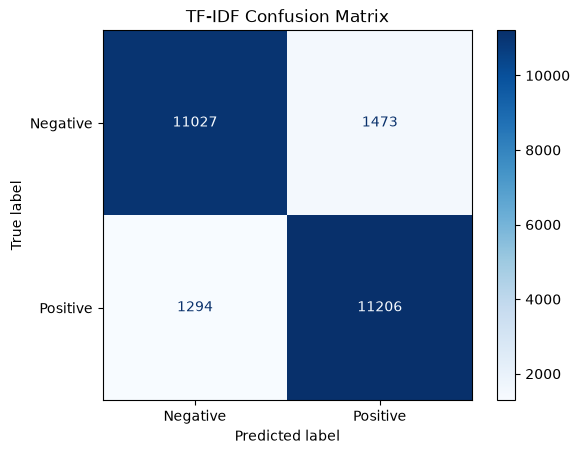

In [19]:
plot_confusion(test_labels, tfidf_test_preds, "TF-IDF Confusion Matrix")


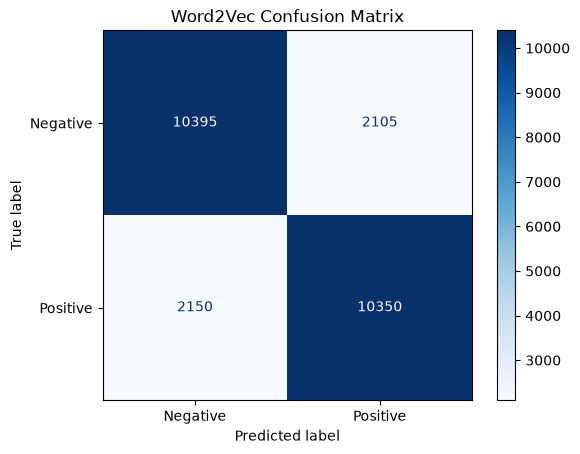

In [20]:
plot_confusion(test_labels, w2v_test_preds, "Word2Vec Confusion Matrix")


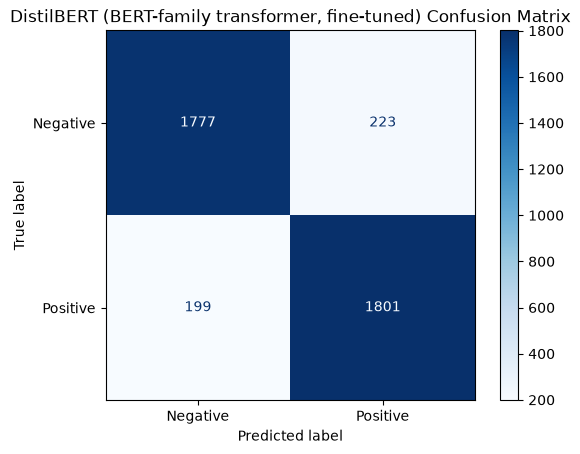

In [21]:
plot_confusion(bert_test_labels, bert_test_preds, f"{BERT_DISPLAY_NAME} Confusion Matrix")


## Error Analysis

For each model we print a small sample of actual misclassified reviews
(false positives and false negatives), using the lightly-cleaned text for
readability. Only discuss patterns you can actually see in the printed
examples below -- don't generalize beyond what's shown.


In [22]:
show_errors(test_texts_bert, test_labels, tfidf_test_preds, "TF-IDF", n=5)


--- TF-IDF: 1473 false positives, 1294 false negatives (out of 25000 test reviews) ---

False Positives (actual=Negative, predicted=Positive) -- up to 5:
  [Actual: Negative | Predicted: Positive] First off let me say, If you haven't enjoyed a Van Damme movie since bloodsport, you probably will not like this movie. Most of these movies may not have the best plots or best actors but I enjoy these kinds of movies for what they are. This movie is much better than any of the movies the other acti...

  [Actual: Negative | Predicted: Positive] Ben, (Rupert Grint), is a deeply unhappy adolescent, the son of his unhappily married parents. His father, (Nicholas Farrell), is a vicar and his mother, (Laura Linney), is ... well, let's just say she's a somewhat hypocritical soldier in Jesus' army. It's only when he takes a summer job as an assis...

  [Actual: Negative | Predicted: Positive] The Forgotten (AKA: Don't Look In The Basement) is a very cheaply made and very old looking horror movie. T

In [23]:
show_errors(test_texts_bert, test_labels, w2v_test_preds, "Word2Vec", n=5)


--- Word2Vec: 2105 false positives, 2150 false negatives (out of 25000 test reviews) ---

False Positives (actual=Negative, predicted=Positive) -- up to 5:
  [Actual: Negative | Predicted: Positive] STAR RATING: ***** Saturday Night **** Friday Night *** Friday Morning ** Sunday Night * Monday Morning Former New Orleans homicide cop Jack Robideaux (Jean Claude Van Damme) is re-assigned to Columbus, a small but violent town in Mexico to help the police there with their efforts to stop a major he...

  [Actual: Negative | Predicted: Positive] First off let me say, If you haven't enjoyed a Van Damme movie since bloodsport, you probably will not like this movie. Most of these movies may not have the best plots or best actors but I enjoy these kinds of movies for what they are. This movie is much better than any of the movies the other acti...

  [Actual: Negative | Predicted: Positive] Isaac Florentine has made some of the best western Martial Arts action movies ever produced. In particula

In [24]:
show_errors(bert_test_texts, bert_test_labels, bert_test_preds, BERT_DISPLAY_NAME, n=5)


--- DistilBERT (BERT-family transformer, fine-tuned): 223 false positives, 199 false negatives (out of 4000 test reviews) ---

False Positives (actual=Negative, predicted=Positive) -- up to 5:
  [Actual: Negative | Predicted: Positive] This only gets bashed because it stars David Hasselhoff. Well, then let me bash it to. Compared to the garbage they call horror coming out nowadays, this film isn't too bad. It has the beautiful Leslie Cumming. She is super hot, but can't talk very well. There is a great scene with her when she is s...

  [Actual: Negative | Predicted: Positive] 1983's "Frightmare" is an odd little film. The director seems to be trying to combine the atmosphere of classic '30s/'40s style horror movies with the shock factor of the then-exploding '80s slasher genre. It isn't totally successful (mostly due to very obvious budgetary restraints, and the less-tha...

  [Actual: Negative | Predicted: Positive] The Kid was born retarded. It pulls in a half-dozen directions, feat

**Observed error patterns (from the printed examples above):**

- **TF-IDF and Word2Vec fail on many of the same reviews.** Both mark the
  "If you haven't enjoyed a Van Damme movie since bloodsport..." review and the
  "Ben, (Rupert Grint), is a deeply unhappy adolescent..." review (both truly Negative)
  as Positive. Both also mark the Mehta *Fire* reviews ("I finally watched the third film
  in Mehta's trilogy...", "in Indian household how most decisions are taken by the
  man...", both truly Positive) as Negative. Both are bag-of-words-style
  representations, so they react to the same surface vocabulary.
- **False positives (true Negative, predicted Positive)** are often hedged genre-fan
  reviews: "I enjoy these kinds of movies for what they are", "this movie was kinda
  enjoyable". Individual clauses read as positive, but the overall verdict is negative.
- **False negatives (true Positive, predicted Negative)** are often reviews that praise
  a film's theme while spending most of the text on criticism. For example: "the depiction ...
  is excellent ... There is a lack of good dialogues ... lack of continuity and lack of
  passion". They also include reviews whose vocabulary is dark (sex, killing, slasher) even
  though the verdict is positive.
- **DistilBERT's remaining errors** are mostly mixed or ironic reviews. Examples: "This only
  gets bashed because it stars David Hasselhoff... this film isn't too bad" (truly
  Negative), "The first 1/3 of this movie I loved..." (truly Negative), and "very good, not
  great but very good" (truly Positive). These are cases where the polarity depends on
  how the whole review is weighed, not on single words.
- **Error counts from this run:** TF-IDF made 1,473 FP + 1,294 FN = 2,767 errors on 25,000
  reviews (11.1%). Word2Vec made 2,105 FP + 2,150 FN = 4,255 errors (17.0%). DistilBERT made
  223 FP + 199 FN = 422 errors on its 4,000-review test subset (10.6%).

## Model Comparison Table

In [25]:
if len(bert_train_texts) != len(train_texts) or len(bert_test_texts) != len(test_texts):
    print(f"NOTE: the transformer was fine-tuned on {len(bert_train_texts)} training reviews and scored on a "
          f"stratified {len(bert_test_texts)}-review test subset (BERT_SUBSET_SIZE={BERT_SUBSET_SIZE}, CPU run). "
          f"TF-IDF and Word2Vec used the full {len(train_texts)} / {len(test_texts)} reviews.")
else:
    print(f"All three models were trained on the same {len(train_texts)} training reviews and "
          f"evaluated on the same {len(test_texts)}-review test set.")

results_df = pd.DataFrame(results).T
results_df = results_df[
    ["Train Samples", "Test Samples", "Accuracy", "Precision", "Recall", "F1-score", "Training Time (s)"]
]
display(results_df)

# Apples-to-apples view: every model scored on the exact same test reviews the transformer saw
sub_y = bert_test_labels
same_subset = {
    "TF-IDF + Logistic Regression": [tfidf_test_preds[i] for i in bert_test_idx],
    "Word2Vec + Logistic Regression": [w2v_test_preds[i] for i in bert_test_idx],
    BERT_DISPLAY_NAME: list(bert_test_preds),
}
subset_df = pd.DataFrame({
    name: {
        "Test Samples": len(sub_y),
        "Accuracy": accuracy_score(sub_y, p),
        "Precision": precision_score(sub_y, p, zero_division=0),
        "Recall": recall_score(sub_y, p, zero_division=0),
        "F1-score": f1_score(sub_y, p, zero_division=0),
    }
    for name, p in same_subset.items()
}).T
print(f"\nAll models on the same {len(sub_y)}-review test subset:")
subset_df

NOTE: the transformer was fine-tuned on 4000 training reviews and scored on a stratified 4000-review test subset (BERT_SUBSET_SIZE=4000, CPU run). TF-IDF and Word2Vec used the full 20000 / 25000 reviews.


,Train Samples,Test Samples,Accuracy,Precision,Recall,F1-score,Training Time (s)
TF-IDF + Logistic Regression,20000.0,25000.0,0.88932,0.883824,0.89648,0.890107,14.6
Word2Vec + Logistic Regression,20000.0,25000.0,0.82980,0.830992,0.82800,0.829493,46.7
"DistilBERT (BERT-family transformer, fine-tuned)",4000.0,4000.0,0.89450,0.889822,0.90050,0.895129,2464.9



All models on the same 4000-review test subset:


,Test Samples,Accuracy,Precision,Recall,F1-score
TF-IDF + Logistic Regression,4000.0,0.88800,0.881890,0.8960,0.888889
Word2Vec + Logistic Regression,4000.0,0.82525,0.826392,0.8235,0.824944
"DistilBERT (BERT-family transformer, fine-tuned)",4000.0,0.89450,0.889822,0.9005,0.895129


## Analysis and Discussion

*(All numbers below come from this notebook's executed outputs: `results_df`, the
same-subset table, the confusion matrices, and the error-analysis printouts. The run
was local and CPU-only. DistilBERT was fine-tuned for 1 epoch on 4,000 training reviews
(`BERT_SUBSET_SIZE = 4000`) and scored on a stratified 4,000-review test subset.
TF-IDF and Word2Vec used the full 20,000 / 25,000 splits.)*

| Model | Train | Test | Accuracy | Precision | Recall | F1 | Train time |
|---|---|---|---|---|---|---|---|
| TF-IDF + LR | 20,000 | 25,000 | 88.93% | 88.38% | 89.65% | 0.8901 | 14.6 s |
| Word2Vec + LR | 20,000 | 25,000 | 82.98% | 83.10% | 82.80% | 0.8295 | 46.7 s |
| DistilBERT (1 epoch, CPU) | 4,000 | 4,000 | 89.45% | 88.98% | 90.05% | 0.8951 | 2,464.9 s |

**Same 4,000-review test subset (apples-to-apples):** TF-IDF 88.80% acc / 0.8889 F1;
Word2Vec 82.53% acc / 0.8249 F1; DistilBERT 89.45% acc / 0.8951 F1.

- **Best performer:** DistilBERT had the highest accuracy and F1 on the shared test subset
  (+0.65 accuracy points over TF-IDF, +6.9 over Word2Vec). It did this with only 4,000
  training reviews and a single epoch, a fifth of the data the other two models
  saw. Its validation accuracy after the epoch was 90.10% (1,000 reviews).
- **TF-IDF is a strong, fast baseline:** 88.93% accuracy on the full 25,000-review test set
  in 14.6 s of training. Sentiment-heavy words carry a lot of signal on their own.
- **Word2Vec (averaged) underperformed both:** 82.98% accuracy / 0.8295 F1. Averaging word
  vectors across a whole review discards word order and dilutes strong sentiment words
  with neutral ones. It makes about 1.5x as many errors as TF-IDF (4,255 vs. 2,767).
- **Precision vs. recall:** TF-IDF and DistilBERT both have recall above precision
  (TF-IDF 89.65% vs. 88.38%; DistilBERT 90.05% vs. 88.98%). Both make slightly
  more false positives than false negatives (1,473 vs. 1,294; 223 vs. 199). Word2Vec is
  nearly balanced (83.10% vs. 82.80%; 2,105 FP vs. 2,150 FN).
- **Training cost:** DistilBERT's 2,464.9 s (about 41 min, 250 optimizer steps on CPU) is
  about 170x TF-IDF's training time, even on one-fifth of the data. On a GPU the same step
  takes minutes, which makes the full 20,000-review run (`BERT_SUBSET_SIZE = None`) and
  full `bert-base-uncased` practical.
- **Memory/compute:** TF-IDF and Word2Vec run comfortably on CPU with modest memory. The
  transformer is the only component that benefits materially from a GPU.
- **Limitation of this run:** the transformer saw less training data and was tested on a
  subset. The same-subset table controls for the test side, but its margin over TF-IDF
  should be read as a lower bound on what a full-data, multi-epoch run would show.

## Final Conclusion

This project compared three text representations for sentiment classification on IMDB
movie reviews: TF-IDF, averaged Word2Vec embeddings, and a fine-tuned transformer
(DistilBERT). The two classical models trained on the full 20,000-review split and were
scored on the full 25,000-review test set. The transformer was fine-tuned on a
4,000-review CPU-friendly subset for one epoch. All three were also compared on the same
4,000-review test subset, using the same four metrics and a fixed random seed.

The ranking is clear. DistilBERT scored best (89.45% accuracy, 0.8951 F1), ahead of
TF-IDF on the same reviews (88.80%, 0.8889) despite seeing a fifth of the training data.
TF-IDF + Logistic Regression was a strong, very cheap baseline: 88.93% accuracy and 0.8901 F1
on all 25,000 test reviews, trained in 14.6 s. Averaged Word2Vec trailed at 82.98% / 0.8295.
Flattening a review into one mean vector loses word order and lets neutral words dilute
sentiment cues.

The transformer's edge cost about 41 minutes of CPU fine-tuning versus seconds for the
classical models. Error analysis shows that the remaining mistakes for every model
concentrate on hedged, mixed, or ironic reviews.

Takeaway: TF-IDF is the right choice when speed and simplicity matter. Word2Vec needs a
better aggregation than plain averaging to compete. A transformer is worth the cost when
accuracy matters and a GPU is available, where `BERT_SUBSET_SIZE = None` and
`bert-base-uncased` can be used for the full comparison.